# 구조화 출력 프롬프트 진단

**이 노트북에서 할 일**

1. 06절 목록의 출력 형식 한 글만 JSON 요청으로 바꾼 목록 세 개를 만듭니다.
2. 답 글을 JSON으로 읽기, 없는 키 찾기, 값 규칙 검사를 차례로 하는 함수를 만들고 직접 적은 글로 확인합니다.
3. 세 목록의 답을 층마다 검사하고, 고객 문의만 바꾼 요청으로 검사를 모두 지난 답의 내용도 읽습니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.

인터넷 서비스에 요청을 모두 4번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.10.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch07-prompt-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

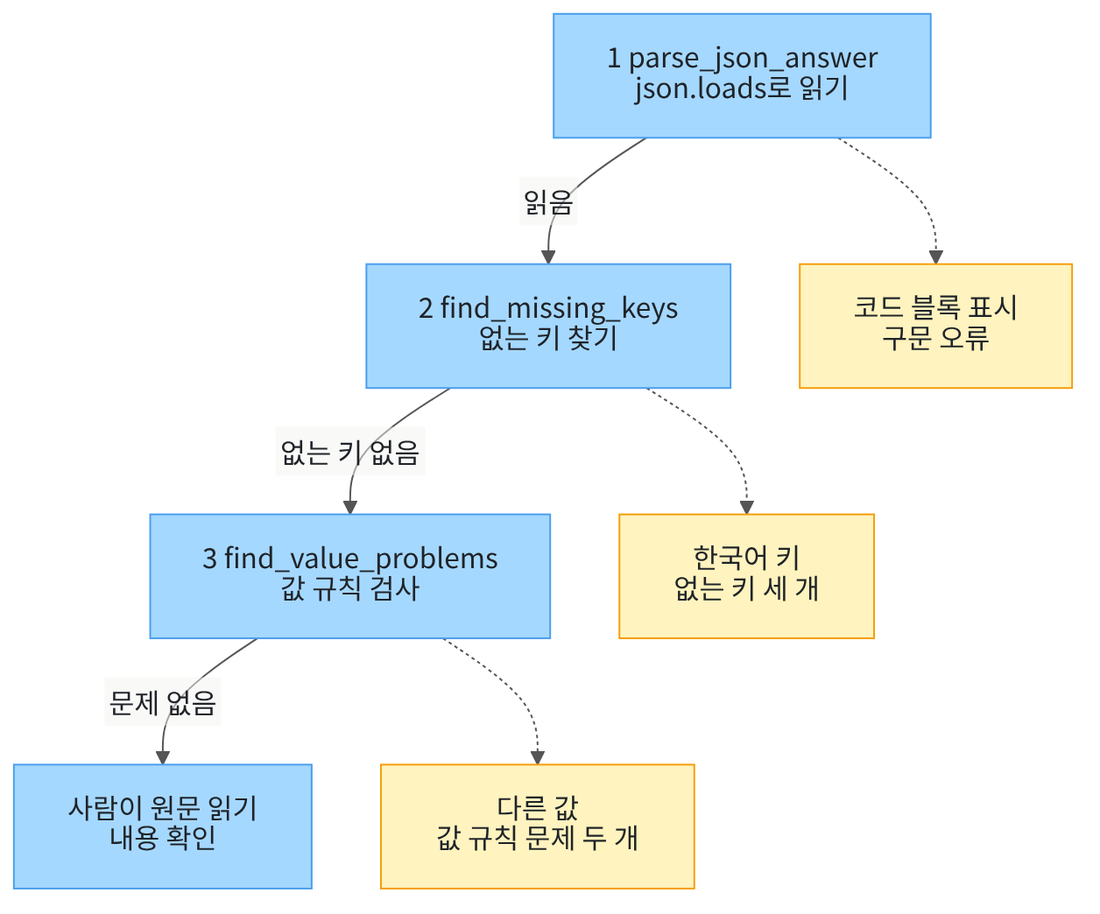

위에서 아래로 읽습니다. 파란 상자 셋은 5절에서 정의하는 검사 함수이고, 앞 층을 지난 답만 다음 층으로 내려갑니다.
세 층을 모두 지난 답은 맨 아래 파란 상자에서 사람이 원문을 읽습니다.

점선 끝의 노란 상자는 5절에서 직접 적은 글이 걸리는 층입니다.
코드 블록 표시 글은 첫 층, 한국어 키 글은 둘째 층, 다른 값 글은 셋째 층에서 걸립니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01~06절과 같은 실습 폴더와 같은 판입니다. 노트북은 앞 절 없이 새 커널에서 시작하므로 다시 확인합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `langchain-openai: 1.6.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

JSON 글을 읽는 모듈 `json`(Ch 6 06절)과 모델 객체를 만드는 함수를 불러옵니다. 앞에서 배운 기록 함수 두 개도 가져옵니다.

앞에서 배운 함수는 `llm_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 Ch 6 06절 `timed_invoke()`와 01절 `make_prompt_record()`를 가져옵니다.

In [2]:
# JSON 글을 읽는 모듈과 모델 객체를 만드는 함수를 불러옵니다
import json

from langchain.chat_models import init_chat_model
# Ch 6 06절·01절 기록 함수 두 개를 도구 파일에서 가져옵니다
from llm_tools import make_prompt_record, timed_invoke

01~06절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01~06절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

인자 `reasoning_effort="none"`도 01~06절과 같습니다. 이 절도 모델 호출 설정은 바꾸지 않습니다.

## 2. 06절 글 다시 만들기

05·06절 목록은 system 페르소나, developer 과업 명세, user 고객 문의 세 메시지였습니다.
과업 명세는 목표·필수 정보·금지 사항·출력 형식 네 글을 줄바꿈으로 이은 글입니다.

이 절은 네 글 가운데 출력 형식 한 글만 바꿉니다. 먼저 06절과 같은 글을 다시 만들고, 바꿀 출력 형식을 출력합니다.

In [5]:
# 06절과 같은 페르소나·고객 문의·과업 명세 글을 다시 만듭니다
persona_text = "당신은 친절한 고객 상담원입니다."
inquiry_text = "어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다."
goal_text = "고객 문의를 분류하고 필요한 다음 행동을 안내하세요."
required_text = "회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요."
forbidden_text = "근거 없는 보상은 약속하지 마세요."
format_text = "분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요."
print("바꿀 출력 형식:", format_text)

바꿀 출력 형식: 분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.


**결과 읽기** — 출력은 `바꿀 출력 형식: 분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.` 한 줄입니다.
05·06절 답만 받는 목록의 출력 형식과 같은 글입니다.

## 3. JSON으로 답하게 하는 출력 형식 세 개

이 절에서 요청할 JSON은 딕셔너리와 비슷한 모양으로 값을 적는 글입니다. Ch 4 04절에서 받은 응답과 Ch 6 06절에서 저장한 기록 파일이 이 모양이었습니다.
프로그램이 모델 답을 이어 받아 쓰려면 답을 이런 모양으로 받는 편이 좋습니다.

출력 형식 글을 세 단계로 만듭니다. 「JSON만」은 JSON으로 답하라고만 적습니다. 「키 이름」은 키 세 개의 이름을 더합니다.

「값 규칙」은 category 값의 허용 이름, 값의 자료형, 코드 블록 표시를 붙이지 말라는 문장을 더합니다.
허용 이름 세 개는 06절 `allowed_labels`와 같습니다. 프로그램이 찾을 키 이름은 `required_keys` 목록에 담습니다.

In [6]:
# JSON 요청 출력 형식 세 개와, 검사에 쓸 키 이름·허용 이름 목록을 만듭니다
json_format_text = "분류, 다음 행동, 고객에게 보낼 한 문장을 JSON으로 답하세요."
keys_format_text = json_format_text + " 키 이름은 category, next_action, customer_message로 적으세요."
rules_format_text = keys_format_text + " category 값은 배송, 교환, 환불 가운데 한 낱말이고, 세 값은 모두 글로 적으세요."
rules_format_text = rules_format_text + " 코드 블록 표시(```)나 설명 글 없이 JSON 객체 하나만 적으세요."
required_keys = ["category", "next_action", "customer_message"]
allowed_labels = ["배송", "교환", "환불"]
print("JSON만:", json_format_text)
print("키 이름:", keys_format_text)
print("값 규칙:", rules_format_text)

JSON만: 분류, 다음 행동, 고객에게 보낼 한 문장을 JSON으로 답하세요.
키 이름: 분류, 다음 행동, 고객에게 보낼 한 문장을 JSON으로 답하세요. 키 이름은 category, next_action, customer_message로 적으세요.
값 규칙: 분류, 다음 행동, 고객에게 보낼 한 문장을 JSON으로 답하세요. 키 이름은 category, next_action, customer_message로 적으세요. category 값은 배송, 교환, 환불 가운데 한 낱말이고, 세 값은 모두 글로 적으세요. 코드 블록 표시(```)나 설명 글 없이 JSON 객체 하나만 적으세요.


**결과 읽기** — 첫 줄은 `JSON만: 분류, 다음 행동, 고객에게 보낼 한 문장을 JSON으로 답하세요.`입니다.
둘째 줄은 같은 글 뒤에 `키 이름은 category, next_action, customer_message로 적으세요.`가 붙습니다.
셋째 줄은 둘째 줄 글 뒤에 허용 이름·자료형 문장과 코드 블록 표시 문장이 붙습니다.

코드 블록 표시는 백틱 세 개(```)로 글을 감싸는 마크다운 표시입니다. 채팅 화면은 이 표시를 코드 상자로 그려 줍니다.
그러나 이 표시가 붙은 글은 JSON 글이 아니어서, 4절에서 보듯 프로그램이 바로 읽지 못합니다.

세 출력 형식으로 과업 명세와 목록을 만듭니다. 목표·필수 정보·금지 사항은 세 목록 모두 같습니다.
마지막 줄은 세 목록의 system·user 메시지가 같은지 확인합니다.

In [7]:
# 출력 형식만 다른 과업 명세 세 개로 메시지 목록 세 개를 만듭니다
task_start_text = goal_text + "\n" + required_text + "\n" + forbidden_text + "\n"
json_messages = [("system", persona_text), ("developer", task_start_text + json_format_text), ("user", inquiry_text)]
keys_messages = [("system", persona_text), ("developer", task_start_text + keys_format_text), ("user", inquiry_text)]
rules_messages = [("system", persona_text), ("developer", task_start_text + rules_format_text), ("user", inquiry_text)]
print("값 규칙 목록의 과업 명세:")
print(rules_messages[1][1])
same_system = json_messages[0] == keys_messages[0] and keys_messages[0] == rules_messages[0]
same_user = json_messages[2] == keys_messages[2] and keys_messages[2] == rules_messages[2]
print("세 목록의 system과 user 메시지가 같은가:", same_system and same_user)
assert same_system and same_user

값 규칙 목록의 과업 명세:
고객 문의를 분류하고 필요한 다음 행동을 안내하세요.
회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요.
근거 없는 보상은 약속하지 마세요.
분류, 다음 행동, 고객에게 보낼 한 문장을 JSON으로 답하세요. 키 이름은 category, next_action, customer_message로 적으세요. category 값은 배송, 교환, 환불 가운데 한 낱말이고, 세 값은 모두 글로 적으세요. 코드 블록 표시(```)나 설명 글 없이 JSON 객체 하나만 적으세요.
세 목록의 system과 user 메시지가 같은가: True


**결과 읽기** — 라벨 줄 `값 규칙 목록의 과업 명세:` 아래 네 줄이 과업 명세입니다. 앞 세 줄은 06절과 같고, 넷째 줄만 JSON 요청입니다.
마지막 줄은 `세 목록의 system과 user 메시지가 같은가: True`입니다.

이름 `task_start_text`는 앞 세 글을 이은 뒤 끝에 줄바꿈 하나를 붙인 글입니다. 여기에 출력 형식 글을 이으면 06절과 같은 네 줄 모양이 됩니다.

## 4. 직접 적은 글을 JSON으로 읽어 보기

요청을 보내기 전에, 직접 적은 글로 JSON 읽기를 확인합니다. 이 셀은 요청을 보내지 않습니다.
함수 `json.loads()`는 JSON 글을 받아 Python 값을 반환합니다. JSON 객체는 딕셔너리, JSON 배열은 목록이 됩니다.

글 안에 큰따옴표가 있어서, 바깥은 작은따옴표로 감쌌습니다. 키 목록은 딕셔너리 메서드 `keys()`의 결과를 `list()`로 바꿔 출력합니다.

In [8]:
# 키 세 개가 모두 맞는 JSON 글을 직접 적고, json.loads()로 읽습니다(요청 없음)
plain_text = '{"category": "교환", "next_action": "파손 사진을 받습니다.", "customer_message": "파손 사진을 보내 주세요."}'
plain_value = json.loads(plain_text)
key_names = list(plain_value.keys())
print("읽은 값 종류:", type(plain_value).__name__)
print("키 목록:", key_names)
print("category 값:", plain_value["category"])

읽은 값 종류: dict
키 목록: ['category', 'next_action', 'customer_message']
category 값: 교환


**결과 읽기** — 세 줄은 `읽은 값 종류: dict`, `키 목록: ['category', 'next_action', 'customer_message']`, `category 값: 교환`입니다.
글이었던 답이 딕셔너리로 바뀌어, 키 이름으로 값을 꺼낼 수 있습니다.

이번에는 같은 글 앞뒤에 코드 블록 표시를 붙여 읽습니다. 읽지 못하면 오류 `json.JSONDecodeError`가 납니다.
오류 이름 가운데 점 앞의 `json`은 이 오류가 `json` 모듈에 있다는 뜻입니다. Python 문서는 이 오류가 `ValueError`의 한 종류라고 적습니다.
Ch 6 01절처럼 오류를 받아 이름과 메시지를 출력하고, 셀은 끝까지 실행합니다.

In [9]:
# 코드 블록 표시를 붙인 글을 읽고, 읽지 못하면 오류 이름과 메시지를 출력합니다(요청 없음)
fenced_text = "```json\n" + plain_text + "\n```"
print("코드 블록 표시를 붙인 글:")
print(fenced_text)
try:
    json.loads(fenced_text)
except json.JSONDecodeError as error:
    print("오류 종류:", type(error).__name__)
    print("오류 메시지:")
    print(error)

코드 블록 표시를 붙인 글:
```json
{"category": "교환", "next_action": "파손 사진을 받습니다.", "customer_message": "파손 사진을 보내 주세요."}
```
오류 종류: JSONDecodeError
오류 메시지:
Expecting value: line 1 column 1 (char 0)


**결과 읽기** — 라벨 줄 아래 세 줄이 코드 블록 표시를 붙인 글입니다. 가운데 줄은 앞 셀의 JSON 글과 같습니다.
그 아래는 `오류 종류: JSONDecodeError`이고, 라벨 줄 `오류 메시지:` 아래는 `Expecting value: line 1 column 1 (char 0)`입니다.

메시지는 첫 줄 첫 글자에서 값이 올 자리를 기대했다는 뜻입니다. 첫 글자가 JSON 값의 시작이 아닌 백틱이라 읽지 못했습니다.
뜻은 같은 답이어도, 글 모양이 조금만 달라지면 프로그램은 읽지 못합니다.

## 5. 층마다 검사하는 함수

답을 이어 받아 쓰려면 세 가지를 차례로 확인합니다. 첫째는 답 글을 JSON으로 읽을 수 있는지입니다.
둘째는 필요한 키가 모두 있는지, 셋째는 값이 정한 규칙을 지키는지입니다. 앞 층을 지나지 못하면 뒤 층은 검사할 수 없습니다.

첫 함수 `parse_json_answer()`는 답 글을 읽어, 읽은 값과 읽기 결과를 튜플로 반환합니다. 읽기 결과는 「읽음」이나 「구문 오류」입니다.
구문 오류는 JSON 글의 문법대로 적히지 않아 읽지 못한 경우입니다. 읽지 못하면 읽은 값은 처음 담은 `None`으로 남습니다.
이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [10]:
# 답 글을 JSON으로 읽어, 읽은 값과 읽기 결과(읽음·구문 오류)를 튜플로 반환하는 함수를 정의합니다
def parse_json_answer(answer_text):
    parsed_value = None
    parse_result = "읽음"
    try:
        parsed_value = json.loads(answer_text)
    except json.JSONDecodeError:
        parse_result = "구문 오류"
    return parsed_value, parse_result

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

둘째 함수 `find_missing_keys()`는 읽은 딕셔너리에 없는 키 이름을 목록으로 반환합니다. 모든 키가 있으면 빈 목록 `[]`입니다.
Part 1에서 목록과 글에 쓴 `in`은 딕셔너리에도 씁니다. 딕셔너리에 쓰면 그 이름의 키가 있는지 봅니다.
이 셀도 함수를 정의만 하므로 출력이 없습니다.

In [11]:
# 읽은 딕셔너리에 없는 키 이름을 목록으로 반환하는 함수를 정의합니다
def find_missing_keys(parsed_value):
    missing_keys = []
    for key in required_keys:
        if key not in parsed_value:
            missing_keys.append(key)
    return missing_keys

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

셋째 함수 `find_value_problems()`는 값 규칙 두 가지를 봅니다. 필요한 키의 값이 글인지, category 값이 허용 이름인지입니다.
글의 자료형 이름은 `str`입니다. Ch 6 01절의 `type(값).__name__`으로 자료형 이름을 꺼내 비교합니다.

06절 `find_label()`처럼 허용 이름과 뜻이 비슷한 값도 고쳐 세지 않습니다. 이 셀도 함수를 정의만 하므로 출력이 없습니다.

In [12]:
# 필요한 키의 값이 글인지, category 값이 허용 이름인지 보고 문제 목록을 반환하는 함수를 정의합니다
def find_value_problems(parsed_value):
    value_problems = []
    for key, key_value in parsed_value.items():
        if key in required_keys and type(key_value).__name__ != "str":
            value_problems.append(key + " 값이 글이 아님")
    if "category" in parsed_value and parsed_value["category"] not in allowed_labels:
        value_problems.append("category 값이 허용 이름 밖")
    return value_problems

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

마지막 함수 `check_layers()`는 앞 세 함수를 차례로 불러 검사 결과를 딕셔너리 한 줄로 만듭니다. 키는 한국어 네 개입니다.
읽은 값이 딕셔너리일 때만 키와 값을 검사합니다. 읽지 못했거나 JSON 배열처럼 다른 값이면 「검사 안 함」으로 남깁니다.

기록의 한국어 키(`JSON 읽기` 등)는 모델 답 JSON의 영어 키(`category` 등)와 다른 것입니다. 이 셀도 출력이 없습니다.

In [13]:
# 세 함수로 답 글을 층마다 검사하고, 결과를 딕셔너리 한 줄로 반환하는 함수를 정의합니다
def check_layers(answer_text):
    parsed_value, parse_result = parse_json_answer(answer_text)
    layer_record = {
        "JSON 읽기": parse_result,
        "값 종류": type(parsed_value).__name__,
        "없는 키": "검사 안 함",
        "값 규칙 문제": "검사 안 함",
    }
    if layer_record["값 종류"] == "dict":
        layer_record["없는 키"] = find_missing_keys(parsed_value)
        layer_record["값 규칙 문제"] = find_value_problems(parsed_value)
    return layer_record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

직접 적은 답 글 다섯 개로 함수를 확인합니다. 이 셀은 요청을 보내지 않습니다.
「한국어 키」는 키 이름만 한국어입니다. 「다른 값」은 next_action 값이 목록이고 category 값이 「기타」입니다. 「배열」은 JSON 배열입니다.

실행 전에 예상합니다. 코드 블록 표시는 구문 오류, 한국어 키는 없는 키 세 개일 것입니다.
다른 값은 값 규칙 문제 두 개, 배열은 키 검사를 하지 않고, 모두 맞음은 문제가 없을 것입니다.

In [14]:
# 직접 적은 답 글 다섯 개를 층마다 검사합니다(요청 없음)
korean_text = '{"분류": "교환", "다음 행동": "파손 사진을 받습니다.", "고객에게 보낼 한 문장": "파손 사진을 보내 주세요."}'
odd_text = '{"category": "기타", "next_action": ["사진 받기", "접수"], "customer_message": "파손 사진을 보내 주세요."}'
array_text = '["교환", "파손 사진을 받습니다."]'
example_texts = [("코드 블록 표시", fenced_text), ("한국어 키", korean_text), ("다른 값", odd_text), ("배열", array_text), ("모두 맞음", plain_text)]
example_layers = []
print("이름 | JSON 읽기 | 값 종류 | 없는 키 | 값 규칙 문제")
for example_name, example_text in example_texts:
    layer_record = check_layers(example_text)
    example_layers.append(layer_record)
    print(example_name, "|", layer_record["JSON 읽기"], "|", layer_record["값 종류"], "|", layer_record["없는 키"], "|", layer_record["값 규칙 문제"])
assert example_layers[0]["JSON 읽기"] == "구문 오류" and example_layers[4]["값 규칙 문제"] == []

이름 | JSON 읽기 | 값 종류 | 없는 키 | 값 규칙 문제
코드 블록 표시 | 구문 오류 | NoneType | 검사 안 함 | 검사 안 함
한국어 키 | 읽음 | dict | ['category', 'next_action', 'customer_message'] | []
다른 값 | 읽음 | dict | [] | ['next_action 값이 글이 아님', 'category 값이 허용 이름 밖']
배열 | 읽음 | list | 검사 안 함 | 검사 안 함
모두 맞음 | 읽음 | dict | [] | []


**결과 읽기** — 라벨 줄 아래 첫 줄은 `코드 블록 표시 | 구문 오류 | NoneType | 검사 안 함 | 검사 안 함`입니다.
둘째 줄 한국어 키는 `['category', 'next_action', 'customer_message'] | []`로 끝납니다. 키 세 개가 모두 없고, 검사할 값도 없습니다.
셋째 줄 다른 값은 `['next_action 값이 글이 아님', 'category 값이 허용 이름 밖']`으로 끝납니다.

넷째 줄 배열은 `읽음 | list | 검사 안 함 | 검사 안 함`입니다. 답 글을 읽었다고 늘 딕셔너리가 되는 것은 아닙니다.
다섯째 줄 모두 맞음은 `모두 맞음 | 읽음 | dict | [] | []`입니다. 예상과 같고, `assert`도 통과했습니다.

## 6. 세 목록을 한 번씩 보내기

준비 셀에서 가져온 함수 두 개로 요청마다 기록 한 줄을 만듭니다. 함수 `timed_invoke()`는 요청을 보내면서 걸린 시간을 재고, 응답 객체와 걸린 초를 튜플로 반환합니다.
함수 `make_prompt_record()`는 조건 이름·응답 객체·걸린 초로 딕셔너리 한 줄을 만듭니다.
키는 `조건`·`답`·`입력 토큰 수`·`출력 토큰 수`·`끝난 이유`·`걸린 초` 여섯 개입니다.

조건 이름과 목록을 튜플로 묶은 목록을 만들고, 05절처럼 `for`로 풀어 한 번씩 보냅니다.
반복문 안에서는 요청을 보내고 기록을 목록에 모으기만 합니다. 답은 요청이 모두 끝난 뒤 다음 셀에서 출력합니다.

실행 전에 예상합니다. 「JSON만」 답은 키 이름이 영어가 아닐 수 있습니다. 「키 이름」과 「값 규칙」 답에는 세 키가 있을 것입니다.

In [15]:
# 세 목록을 한 번씩 보내고, 기록을 목록에 모읍니다(요청 3번)
condition_lists = [("JSON만", json_messages), ("키 이름", keys_messages), ("값 규칙", rules_messages)]
json_records = []
for condition, input_messages in condition_lists:
    run_response, run_elapsed = timed_invoke(model, input_messages)
    record = make_prompt_record(condition, run_response, run_elapsed)
    json_records.append(record)
print("모은 기록 수:", len(json_records))

모은 기록 수: 3


**결과 읽기** — 출력은 `모은 기록 수: 3` 한 줄입니다. 요청 3번이 모두 끝난 뒤에 출력했습니다.

세 답을 차례로 출력합니다. 조건마다 이름 줄을 먼저 출력하고, 그 아래에 답 글을 그대로 출력합니다.

In [16]:
# 세 조건의 답 글을 그대로 출력합니다
for record in json_records:
    print(record["조건"], "답:")
    print(record["답"])

JSON만 답:
{"분류":"교환 요청","다음 행동":"파손 상태를 확인할 수 있는 사진을 보내주시면 교환 접수를 도와드리겠습니다. 주문번호 A-1042로 확인하겠습니다.","고객에게 보낼 한 문장":"주문번호 A-1042 확인했습니다. 교환 접수를 위해 깨진 뚜껑의 파손 사진을 보내주시면 바로 안내드리겠습니다."}
키 이름 답:
{"category":"교환 요청","next_action":"파손 사진과 주문번호 A-1042를 확인한 뒤 교환 접수를 진행하세요.","customer_message":"주문번호 A-1042 확인했습니다. 교환 접수를 위해 깨진 뚜껑의 파손 사진을 보내주시면 확인 후 안내드리겠습니다."}
값 규칙 답:
{"category":"교환","next_action":"주문번호 A-1042의 교환 접수를 위해 깨진 뚜껑의 파손 사진을 보내주시면 확인 후 새 상품 교환 절차를 안내드리겠습니다.","customer_message":"주문번호 A-1042의 교환을 원하시면 깨진 뚜껑의 파손 사진을 보내주세요."}


**결과 읽기** — 라벨 줄 `JSON만 답:` 아래 답은 `{"분류":"교환 요청"`으로 시작합니다. 키 이름을 적지 않자 한국어 키 세 개로 답했습니다.
라벨 줄 `키 이름 답:` 아래 답은 `{"category":"교환 요청"`으로 시작합니다. `값 규칙 답:` 아래 답은 `{"category":"교환"`으로 시작합니다.

세 답 모두 코드 블록 표시 없이 중괄호로 시작하고 끝납니다. 세 답 모두 보상 약속은 없었습니다.

교재를 만들 때 탐색 실행과 앞선 새 커널 실행에서도 키 모양은 같았습니다. 「JSON만」은 한국어 키, 나머지 둘은 영어 키 세 개였습니다.

값 글은 실행마다 조금씩 달랐습니다. 「키 이름」 답의 분류 값은 앞선 새 커널 실행에서 「교환/파손」이었습니다.

## 7. 기록표와 입력 토큰 차이

세 기록을 01~06절과 같은 기록표 모양으로 출력합니다. 마지막 두 줄은 출력 형식 문장을 더할 때마다 늘어난 입력 토큰 수입니다.
실행 전에 예상합니다. 문장을 더한 「키 이름」과 「값 규칙」 순서로 입력 토큰 수가 늘 것입니다.

In [17]:
# 세 기록을 기록표 모양으로 출력하고, 앞 조건보다 늘어난 입력 토큰 수를 계산합니다
print("기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):")
for record in json_records:
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", record["끝난 이유"], "|", record["걸린 초"])
keys_added = json_records[1]["입력 토큰 수"] - json_records[0]["입력 토큰 수"]
rules_added = json_records[2]["입력 토큰 수"] - json_records[1]["입력 토큰 수"]
print("키 이름 문장이 더한 입력 토큰 수:", keys_added)
print("값 규칙 문장이 더한 입력 토큰 수:", rules_added)

기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):
JSON만 | 130 | 95 | stop | 1.21
키 이름 | 145 | 75 | stop | 0.89
값 규칙 | 191 | 87 | stop | 1.02
키 이름 문장이 더한 입력 토큰 수: 15
값 규칙 문장이 더한 입력 토큰 수: 46


**결과 읽기** — 라벨 줄 아래 세 줄은 `JSON만 | 130 | 95 | stop | 1.21`, `키 이름 | 145 | 75 | stop | 0.89`, `값 규칙 | 191 | 87 | stop | 1.02`입니다.
마지막 두 줄은 `키 이름 문장이 더한 입력 토큰 수: 15`와 `값 규칙 문장이 더한 입력 토큰 수: 46`입니다.

예상대로 입력 토큰 수는 문장을 더한 순서로 늘었습니다. 06절의 세 줄 출력 형식 목록은 입력 134였으니, 「JSON만」 목록이 4 적습니다.
출력 토큰 수는 입력 순서와 같지 않았습니다. 이번에는 「JSON만」 답이 95로 가장 길었고, 앞선 새 커널 실행에서는 95·93·91이었습니다.
걸린 초는 한 번 잰 값이라 속도 비교에 쓰지 않습니다.

Ch 6 07절에서는 양식 클래스를 붙이자 입력이 61에서 190토큰으로 늘었습니다. 양식이 요청에 함께 실리기 때문입니다.
190은 Ch 6 07절 노트북 출력이고, 61은 작업 중 기기 셸에서 한 번 잰 값이라 Ch 6 07절 본문에만 있습니다.
이 절은 양식 대신 출력 형식 글로 요청했습니다. 질문이 달라 두 절의 토큰 수를 직접 비교하지는 않습니다.

## 8. 세 답을 층마다 검사하기

5절의 `check_layers()` 함수로 세 답을 검사합니다. 직접 적은 글과 같은 표 모양으로 출력합니다.
마지막 줄의 `assert`는 세 답을 모두 검사했는지만 확인합니다. 검사 결과가 무엇인지는 확인하지 않습니다.

In [18]:
# 세 답을 층마다 검사해 표로 출력합니다
answer_layers = []
print("조건 | JSON 읽기 | 값 종류 | 없는 키 | 값 규칙 문제")
for record in json_records:
    layer_record = check_layers(record["답"])
    answer_layers.append(layer_record)
    print(record["조건"], "|", layer_record["JSON 읽기"], "|", layer_record["값 종류"], "|", layer_record["없는 키"], "|", layer_record["값 규칙 문제"])
assert len(answer_layers) == len(json_records)

조건 | JSON 읽기 | 값 종류 | 없는 키 | 값 규칙 문제
JSON만 | 읽음 | dict | ['category', 'next_action', 'customer_message'] | []
키 이름 | 읽음 | dict | [] | ['category 값이 허용 이름 밖']
값 규칙 | 읽음 | dict | [] | []


**결과 읽기** — 라벨 줄 아래 첫 줄은 `JSON만 | 읽음 | dict | ['category', 'next_action', 'customer_message'] | []`입니다.
답 글은 JSON으로 읽었지만, 프로그램이 찾는 키가 세 개 모두 없습니다.
둘째 줄은 `키 이름 | 읽음 | dict | [] | ['category 값이 허용 이름 밖']`입니다. 키는 모두 있지만, category 값 「교환 요청」이 허용 이름이 아닙니다.
셋째 줄은 `값 규칙 | 읽음 | dict | [] | []`로, 세 층을 모두 지났습니다.

세 답 모두 구문 오류는 없었습니다. 탐색 실행과 앞선 새 커널 실행에서도 층별 결과는 이번과 같았습니다.
그래서 구문 오류 층은 4·5절의 직접 적은 글로만 확인했습니다. 모델 답에서 구문 오류가 나는 경우는 이번에 보지 못했습니다.

## 9. 검사를 모두 지난 답의 내용 읽기

세 층을 모두 지났다고 답 내용까지 맞는 것은 아닙니다. 코드는 키와 값의 모양만 봤기 때문입니다.
「값 규칙」 답을 다시 읽어, 키마다 값을 한 줄씩 출력합니다. 값이 여러 줄이 아니라서 라벨과 같은 줄에 출력합니다.

In [19]:
# 「값 규칙」 답을 읽어, 키마다 값을 한 줄씩 출력합니다
rules_value, rules_parse_result = parse_json_answer(json_records[2]["답"])
print("읽기 결과:", rules_parse_result)
for key in required_keys:
    print(key + ":", rules_value[key])

읽기 결과: 읽음
category: 교환
next_action: 주문번호 A-1042의 교환 접수를 위해 깨진 뚜껑의 파손 사진을 보내주시면 확인 후 새 상품 교환 절차를 안내드리겠습니다.
customer_message: 주문번호 A-1042의 교환을 원하시면 깨진 뚜껑의 파손 사진을 보내주세요.


**결과 읽기** — 첫 줄은 `읽기 결과: 읽음`, 둘째 줄은 `category: 교환`입니다.
셋째 줄은 `next_action: 주문번호 A-1042의 교환 접수를 위해`로 시작합니다.
넷째 줄은 `customer_message: 주문번호 A-1042의 교환을 원하시면`으로 시작합니다.

원문을 읽으면 두 값의 역할이 겹칩니다. 다음 행동 값도 「사진을 보내주시면 확인 후 … 안내드리겠습니다」처럼 고객에게 하는 말입니다.
6절 「키 이름」 답의 다음 행동 값은 「… 확인한 뒤 교환 접수를 진행하세요」처럼 상담원이 할 일이었습니다.
과업 명세는 다음 행동이 상담원의 할 일인지 고객에게 하는 안내인지 정하지 않았습니다.
그래서 이 차이는 모델 잘못이라기보다, 키의 뜻을 출력 형식에 적어야 한다는 신호로 읽습니다.

코드는 값이 글인지만 봤으므로 이 차이를 잡지 못합니다. 앞선 새 커널 실행에서는 「값 규칙」 답의 다음 행동 값도 상담원이 할 일이었습니다.
같은 목록에서도 말투가 실행마다 달랐고, 이번 두 실행에서 본 모양으로만 적습니다.

01절 확인 단어 세 개가 세 답에 있는지 표시합니다. 이 표시도 품질 점수가 아니라, 원문을 읽을 곳을 찾는 도구입니다.

In [20]:
# 확인 단어 세 개가 세 조건의 답에 있는지 표시합니다
check_words = ["교환", "A-1042", "사진"]
print("확인 단어 | JSON만 · 키 이름 · 값 규칙 답에 있는가")
for word in check_words:
    word_flags = []
    for record in json_records:
        word_flags.append(word in record["답"])
    print(word, "|", word_flags)

확인 단어 | JSON만 · 키 이름 · 값 규칙 답에 있는가
교환 | [True, True, True]
A-1042 | [True, True, True]
사진 | [True, True, True]


**결과 읽기** — 라벨 줄 아래 세 줄은 `교환 | [True, True, True]`, `A-1042 | [True, True, True]`, `사진 | [True, True, True]`입니다.
세 답 모두 세 단어가 있어, 표시로는 조건 사이의 차이가 보이지 않습니다.

「JSON만」 답은 키 층을 지나지 못했는데도 표시는 다른 두 답과 같습니다.
낱말이 답에 있는지와, 프로그램이 그 값을 키로 꺼낼 수 있는지는 다른 질문입니다.

## 10. 값 바꿔 보기 — 고객 문의만 바꾸기

바꾸는 값은 user 메시지의 고객 문의 하나입니다. 03절에서 관련 없는 예시로 쓴 「뉴스레터 글꼴을 바꾸고 싶습니다.」를 보냅니다.
system 페르소나와 「값 규칙」 과업 명세는 그대로 둡니다. 이 문의에는 배송·교환·환불 가운데 맞는 분류가 없습니다.

실행 전에 예상합니다. 출력 형식이 category를 세 이름 가운데 하나로 적게 했습니다. 그래서 답은 세 층을 지나도, 분류는 문의와 맞지 않을 것입니다.

In [21]:
# 고객 문의만 글꼴 문의로 바꾼 목록을 보내고, 답과 층별 검사 결과를 출력합니다(요청 1번)
font_inquiry_text = "뉴스레터 글꼴을 바꾸고 싶습니다."
font_messages = [("system", persona_text), ("developer", rules_messages[1][1]), ("user", font_inquiry_text)]
font_response, font_elapsed = timed_invoke(model, font_messages)
font_record = make_prompt_record("값 규칙 + 글꼴 문의", font_response, font_elapsed)
font_layer = check_layers(font_record["답"])
print("글꼴 문의 답:")
print(font_record["답"])
print("JSON 읽기 | 없는 키 | 값 규칙 문제:", font_layer["JSON 읽기"], "|", font_layer["없는 키"], "|", font_layer["값 규칙 문제"])
print("입력 토큰 수 | 출력 토큰 수:", font_record["입력 토큰 수"], "|", font_record["출력 토큰 수"])

글꼴 문의 답:
{"category":"배송","next_action":"뉴스레터 글꼴 변경은 주문 관련 문의가 아니므로 담당 부서 안내가 필요합니다. 주문번호가 있다면 함께 확인해 주세요.","customer_message":"뉴스레터 글꼴 변경은 주문/배송 문의와는 별도라서 담당 부서 확인이 필요합니다. 주문번호가 있으시면 함께 보내 주세요."}
JSON 읽기 | 없는 키 | 값 규칙 문제: 읽음 | [] | []
입력 토큰 수 | 출력 토큰 수: 169 | 82


**결과 읽기** — 라벨 줄 `글꼴 문의 답:` 아래 답은 `{"category":"배송"`으로 시작합니다.
다음 줄은 `JSON 읽기 | 없는 키 | 값 규칙 문제: 읽음 | [] | []`이고, 마지막 줄은 `입력 토큰 수 | 출력 토큰 수: 169 | 82`입니다.
세 층을 모두 지났으므로, 코드 검사로는 문제가 없습니다.

입력 토큰 169는 「값 규칙」 목록의 191보다 22 적습니다. 바꾼 것은 고객 문의 글 하나라, 짧아진 문의 글의 몫입니다.

검사를 지난 답이므로 category 값을 꺼내 봅니다. 규칙은 지켰지만 문의와 맞는 분류인지는 원문을 읽고 판단합니다.

In [22]:
# 글꼴 문의 답의 category 값과 next_action 값을 꺼냅니다
font_value, font_parse_result = parse_json_answer(font_record["답"])
print("category 값:", font_value["category"])
print("category 값이 허용 이름인가:", font_value["category"] in allowed_labels)
print("next_action 값:", font_value["next_action"])

category 값: 배송
category 값이 허용 이름인가: True
next_action 값: 뉴스레터 글꼴 변경은 주문 관련 문의가 아니므로 담당 부서 안내가 필요합니다. 주문번호가 있다면 함께 확인해 주세요.


**결과 읽기** — 첫 두 줄은 `category 값: 배송`과 `category 값이 허용 이름인가: True`입니다.
셋째 줄은 `next_action 값: 뉴스레터 글꼴 변경은 주문 관련 문의가 아니므로`로 시작합니다.

답은 고객 문장 값에 「주문/배송 문의와는 별도」라고 적으면서, 분류 값에는 배송을 적었습니다. 실행 전에 예상한 대로입니다.
허용 이름 셋 가운데 이 문의에 맞는 이름이 없어, 규칙을 지킨 답은 어느 이름을 적어도 문의와 맞지 않습니다.
탐색 실행에서는 같은 목록의 분류 값이 환불이었고, 앞선 새 커널 실행에서는 배송이었습니다.
셋 가운데 어느 이름을 고르는지는 실행마다 달랐고, 그 까닭은 단정하지 않습니다.

세 번 모두 세 층을 지났지만, 글꼴 문의와 맞는 분류는 아니었습니다. 이것은 사람이 문의와 답을 읽고 한 판단입니다.
모양은 맞지만 업무와 맞지 않는 답을 이 절에서는 내용 오류라고 부릅니다.
허용 이름에 「기타」 같은 이름을 더할지는 표를 세기 전에 정할 일이고, 이번에 실행하지 않았습니다.

## 실험 결과 해석

출력 형식 한 글만 바꿔 세 목록을 보냈습니다. 세 답은 모두 JSON으로 읽혔고, 구문 오류는 없었습니다.
「JSON만」 답은 한국어 키라 키 층에서, 「키 이름」 답은 분류 값 「교환 요청」 때문에 값 층에서 걸렸습니다.
키 이름과 허용 이름까지 적은 「값 규칙」 답만 세 층을 지났고, 그만큼 입력은 130에서 191토큰으로 늘었습니다.

답이 JSON으로 읽힌다는 것과 프로그램이 그 답을 쓸 수 있다는 것은 다릅니다. 층을 나눠 보면 어느 문장을 더 적어야 할지 보입니다.

세 층을 지난 답도 내용은 따로 봐야 했습니다. 「값 규칙」 답의 다음 행동 값은 고객에게 하는 말이었습니다.
글꼴 문의에는 허용 이름 가운데 맞는 분류가 없었고, 답은 분류 값에 배송을 적었습니다.

이 결론은 고객 문의 두 개·모델 하나·목록마다 한 번 실행한 범위입니다. 구문 오류는 모델 답에서 보지 못해 직접 적은 글로만 확인했습니다.
출력 형식 글로 요청한 JSON이 늘 이 모양이라고 하지 않습니다. 걸린 초도 한 번 잰 값이라 속도 비교에 쓰지 않습니다.

## 정리

- 직접 적은 글 다섯 개로, JSON 읽기·없는 키·값 규칙 세 층의 검사 함수를 확인했습니다.
- 출력 형식만 바꾼 세 답은 모두 JSON으로 읽혔고, 「값 규칙」 답만 세 층을 지났습니다.
- 세 층을 지난 답에도 역할이 겹친 값과 문의에 맞지 않는 분류가 있어, 내용은 원문으로 확인했습니다.

다음 08절에서는 프롬프트 문구와 바꾼 이유를 버전으로 기록하고, 세 버전을 같은 항목으로 비교합니다.